In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

## 1-2. Чтение данных

In [28]:
train_df = pd.read_parquet(
    r"D:\Astro HSE\Data\StarEmbed_final_train.parquet",
    engine='fastparquet'
)
test_df = pd.read_parquet(
    r"D:\Astro HSE\Data\StarEmbed_final_test.parquet",
    engine='fastparquet'
)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("\nColumns:", train_df.columns.tolist())
print("\nFirst rows:")
print(train_df.head())

Train shape: (28921, 10)
Test shape: (8288, 10)

Columns: ['object_id', 'object_class', 'class_name', 'period', 'csdr1_id', 'lightcurve.mjd', 'lightcurve.passband', 'lightcurve.flux', 'lightcurve.flux_err', 'lightcurve.lgwave']

First rows:
            object_id  object_class class_name    period  \
0  102311274853951453             1         EW  0.236962   
1  135570608727928867             1         EW  0.314820   
2   93350774089063978             8     RS CVn  0.339501   
3  165402610129609440             5        RRc  0.369517   
4  121091256653385076             1         EW  0.274364   

               csdr1_id                                     lightcurve.mjd  \
0  CSS_J082956.4-044426  [58204.203125, 58204.2265625, 58207.26953125, ...   
1  CSS_J040329.4+225855  [58204.13671875, 58204.15625, 58322.46484375, ...   
2  CSS_J050938.1-121219  [58206.13671875, 58365.46484375, 58368.5, 5837...   
3  CSS_J172403.2+475024  [58204.4375, 58204.453125, 58204.46875, 58204....   
4  CSS_J

## 3. Визуализация кривой блеска по id

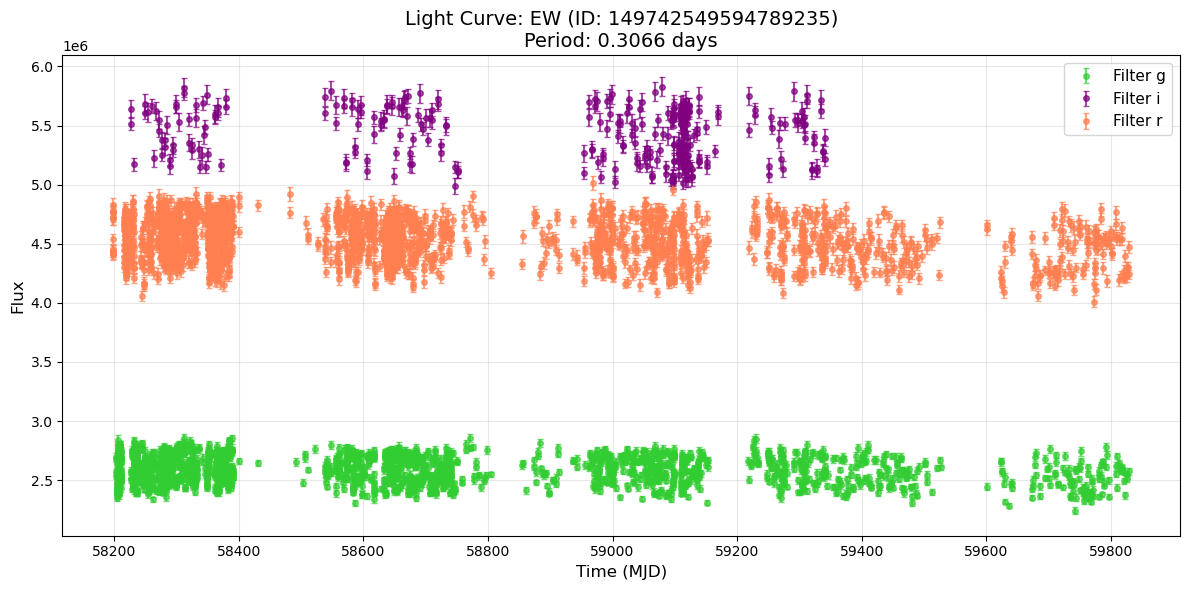

In [29]:
# Словарь цветов для фильтров ZTF
FILTER_COLORS = {'g': 'limegreen', 'r': 'coral', 'i': 'purple'}

def plot_lightcurve_advanced(df, object_id):
    """
    Продвинутая визуализация кривой блеска по object_id с разделением по фильтрам.
    """
    mask = df['object_id'] == object_id
    if not mask.any():
        print(f"Объект {object_id} не найден!")
        return
    
    obj = df[mask].iloc[0]
    
    mjd = np.array(obj['lightcurve.mjd'])
    flux = np.array(obj['lightcurve.flux'])
    flux_err = np.array(obj['lightcurve.flux_err'])
    passband = np.array(obj['lightcurve.passband'])
    
    plt.figure(figsize=(12, 6))
    
    # Рисуем каждый фильтр своим цветом
    unique_filters = np.unique(passband)
    for p in unique_filters:
        p_mask = passband == p
        color = FILTER_COLORS.get(p, 'gray')
        
        plt.errorbar(
            mjd[p_mask], flux[p_mask], yerr=flux_err[p_mask], 
            fmt='o', markersize=4, alpha=0.7, label=f'Filter {p}', 
            color=color, capsize=2, ecolor=color
        )
    
    plt.title(f"Light Curve: {obj['class_name']} (ID: {object_id})\nPeriod: {obj['period']:.4f} days", fontsize=14)
    plt.xlabel("Time (MJD)", fontsize=12)
    plt.ylabel("Flux", fontsize=12)
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Проверка по номеру строки
test_id = train_df['object_id'].iloc[1000]
plot_lightcurve_advanced(train_df, test_id)

## 4. Сбор статистик

In [30]:
def extract_lightcurve_stats(row):
    """
    Извлекает статистики из одной строки
    """
    mjd = np.array(row['lightcurve.mjd'])
    passband = np.array(row['lightcurve.passband'])
    
    n_obs = len(mjd)
    
    # 4.4: Длительность
    duration = float(mjd.max() - mjd.min()) if n_obs > 0 else 0.0
    
    # 4.3: Количество наблюдений в каждом фильтре
    unique_pb, counts = np.unique(passband, return_counts=True)
    obs_per_filter = dict(zip(unique_pb, counts))
    
    # 4.5: Cadence? (среднее и медиана разностей между соседними наблюдениями по фильтрам)
    cadence_mean = {}
    cadence_median = {}
    cadence = {}
    
    
    for p in unique_pb:
        p_mask = passband == p
        p_mjd = np.sort(mjd[p_mask])
        
        if len(p_mjd) > 1:
            diffs = np.diff(p_mjd)
            cadence[p] = diffs
            cadence_mean[p] = float(np.mean(diffs))
            cadence_median[p] = float(np.median(diffs))
        else:
            cadence[p] = []
            cadence_mean[p] = np.nan
            cadence_median[p] = np.nan
            
    return {
        'object_id': row['object_id'],
        'class_name': row['class_name'],              # 4.1: Класс
        'period': float(row['period']),               # 4.6: Период
        'n_obs': n_obs,                               # 4.2: Общее кол-во наблюдений
        'duration_days': duration,                    # 4.4: Длительность
        'obs_per_filter': obs_per_filter,             # 4.3: Словарь {фильтр: кол-во}
        'cadence': cadence,                           # 4.5: Временные промежутбки между измерениями
        'cadence_mean': cadence_mean,                 # 4.5: Словарь {фильтр: среднее}
        'cadence_median': cadence_median              # 4.5: Словарь {фильтр: медиана}
    }

print("Извлекаем статистики для Train... ")
train_stats = pd.DataFrame(train_df.apply(extract_lightcurve_stats, axis=1).tolist())

print("Извлекаем статистики для Test...")
test_stats = pd.DataFrame(test_df.apply(extract_lightcurve_stats, axis=1).tolist())

print("Готово! Пример итоговой таблицы данных:")
display(train_stats.head(3))

Извлекаем статистики для Train... 
Извлекаем статистики для Test...
Готово! Пример итоговой таблицы данных:


,object_id,class_name,period,n_obs,duration_days,obs_per_filter,cadence,cadence_mean,cadence_median
0,102311274853951453,EW,0.236962,583,1498.980469,"{'g': 252, 'r': 331}","{'g': [0.0234375, 3.04296875, 0.01171875, 2.96...","{'g': 5.972033740039841, 'r': 4.487855113636364}","{'g': 1.99609375, 'r': 1.015625}"
1,135570608727928867,EW,0.314820,1034,1625.355469,"{'g': 310, 'r': 724}","{'g': [0.01953125, 118.30859375, 15.9765625, 2...","{'g': 5.260050060679611, 'r': 2.0885254581604427}","{'g': 1.99609375, 'r': 0.00390625}"
2,93350774089063978,RS CVn,0.339501,714,1621.347656,"{'g': 347, 'r': 367}","{'g': [159.328125, 3.03515625, 3.00390625, 2.9...","{'g': 4.680184248554913, 'r': 4.0109929986338795}","{'g': 0.994140625, 'r': 0.98046875}"


## 5. Визуализация статистик

In [31]:
from collections import defaultdict

def get_filter_distribution(dataset, stat_name, cadence = False):
    """
    Получает распределение статистики по фильтрам для всего датафрейма
    """
    
    list_of_dicts = dataset[stat_name].tolist()
    
    merged_data = defaultdict(list)
    
    if cadence:
        for d in list_of_dicts:
            for key, value in d.items():
                merged_data[key].extend(value)
    else:
        for d in list_of_dicts:
            for key, value in d.items():
                    merged_data[key].append(value)
                
    return merged_data

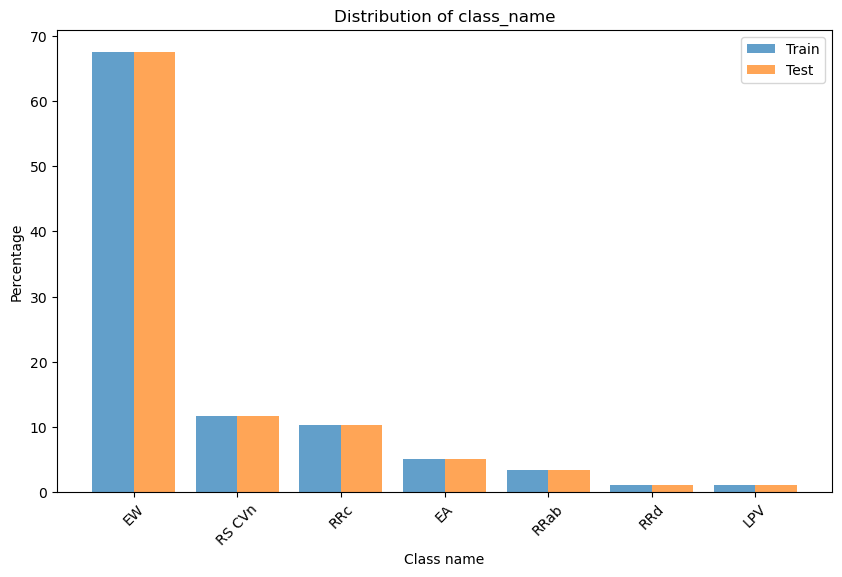

In [32]:
os.makedirs('images', exist_ok=True)

plt.figure(figsize=(10, 6))

train_normalised = train_stats['class_name'].value_counts(normalize=True) * 100
test_normalised = test_stats['class_name'].value_counts(normalize=True) * 100

all_classes = train_stats['class_name'].unique()

bar_width = 0.4

x = np.arange(len(all_classes))

plt.bar(x - bar_width/2, train_normalised, width = bar_width, label = 'Train', alpha = 0.7)
plt.bar(x + bar_width/2, test_normalised, width = bar_width, label = 'Test', alpha = 0.7)

plt.title('Distribution of class_name')
plt.ylabel('Percentage')
plt.xlabel('Class name')
plt.xticks(x, all_classes, rotation=45)
plt.legend()
plt.savefig('images/Distribution of class_name.png')
plt.show()

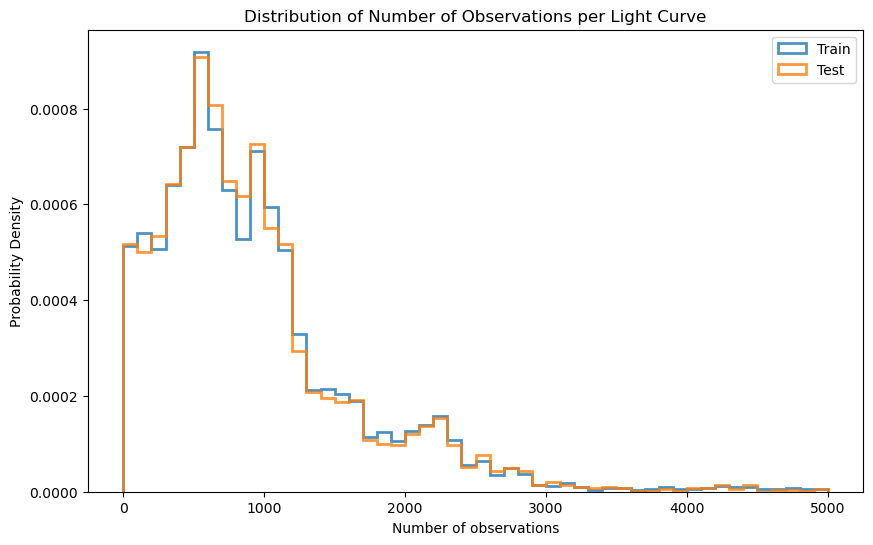

In [33]:
#Cтроим распределение 
plt.figure(figsize=(10, 6))
plt.title('Distribution of Number of Observations per Light Curve')

# Обрезаем до 5000 наблюдений
plt.hist(train_stats['n_obs'], bins=50, density=True, histtype='step', 
         linewidth=2, label='Train', alpha=0.8, range=(0, 5000))
plt.hist(test_stats['n_obs'], bins=50, density=True, histtype='step', 
         linewidth=2, label='Test', alpha=0.8, range=(0, 5000))

plt.ylabel('Probability Density')
plt.xlabel('Number of observations')
plt.legend()
plt.savefig('images/Distribution of n_obs.png')
plt.show()

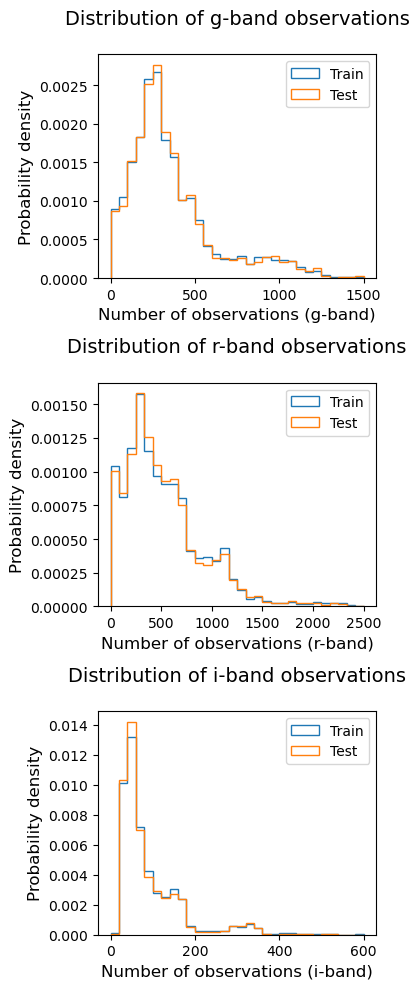

In [34]:
filter_dist = get_filter_distribution(dataset = train_stats, stat_name = 'obs_per_filter', )
filter_dist_test = get_filter_distribution(dataset = test_stats, stat_name = 'obs_per_filter', )
cut = [1500, 2500, 600]


fig, axes = plt.subplots(3, 1, figsize=(4, 10))
plt.title('Distribution of obs_per_filter')

for idx, (filter_name, counts) in enumerate(filter_dist.items()):
    axes[idx].hist(counts, histtype = 'step', bins=30, density = True, label = 'Train', range = (0, cut[idx]) )
    axes[idx].hist(filter_dist_test[filter_name], histtype = 'step', bins=30, density = True, label = 'Test', range = (0, cut[idx]))

    axes[idx].set_xlabel(f'Number of observations ({filter_name}-band)', fontsize=12)
    axes[idx].set_ylabel('Probability density', fontsize=12)
    axes[idx].set_title(f'Distribution of {filter_name}-band observations\n', 
                       fontsize=14)
    axes[idx].legend()

plt.tight_layout()
plt.savefig('images/Distributions of observations per filter')
plt.show()

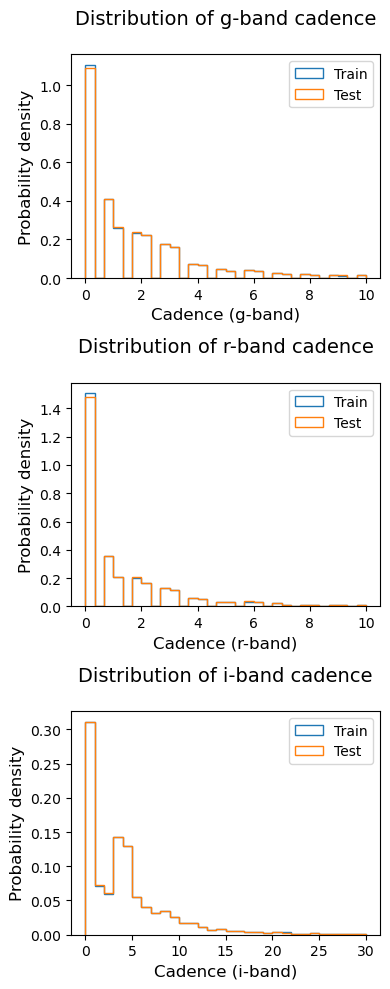

In [35]:
filter_dist = get_filter_distribution(dataset = train_stats, stat_name = 'cadence', cadence = True )
filter_dist_test = get_filter_distribution(dataset = test_stats, stat_name = 'cadence', cadence = True)
cut = [10, 10, 30]

fig, axes = plt.subplots(3, 1, figsize=(4, 10))

for idx, (filter_name, counts) in enumerate(filter_dist.items()):
    axes[idx].hist(np.array(counts), histtype = 'step', bins=30, density = True, label = 'Train', range = (0, cut[idx]))
    axes[idx].hist(np.array(filter_dist_test[filter_name]), histtype = 'step', bins=30, density = True, label = 'Test', range = (0, cut[idx]))

    axes[idx].set_xlabel(f'Cadence ({filter_name}-band)', fontsize=12)
    axes[idx].set_ylabel('Probability density', fontsize=12)
    axes[idx].set_title(f'Distribution of {filter_name}-band cadence\n', 
                       fontsize=14)
    axes[idx].legend()
    
plt.tight_layout()
plt.savefig('images/Distribution of cadence per filter.png')
plt.show()

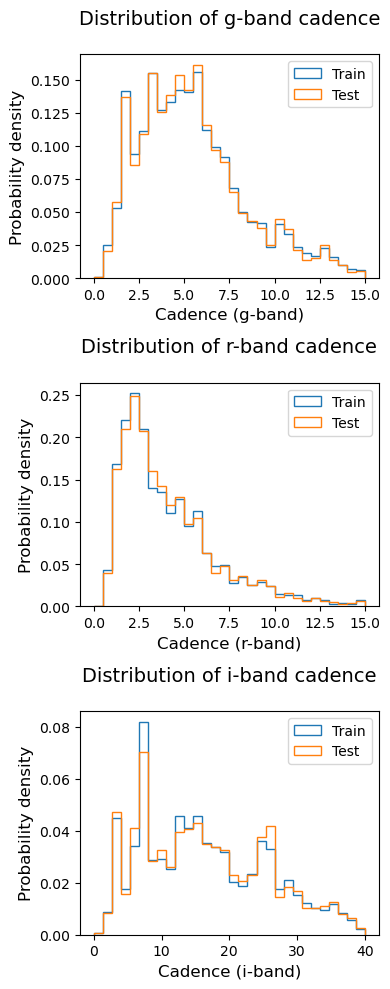

In [36]:
filter_dist = get_filter_distribution(dataset = train_stats, stat_name = 'cadence_mean')
filter_dist_test = get_filter_distribution(dataset = test_stats, stat_name = 'cadence_mean')
cut = [15, 15, 40]


fig, axes = plt.subplots(3, 1, figsize=(4, 10))
plt.title('Distribution of cadence_mean')

for idx, (filter_name, counts) in enumerate(filter_dist.items()):
            
    axes[idx].hist(np.array(counts), histtype = 'step', bins=30, density = True, label = 'Train', range = (0, cut[idx]))
    axes[idx].hist(np.array(filter_dist_test[filter_name]), histtype = 'step', bins=30, density = True, label = 'Test', range =(0, cut[idx]))

    axes[idx].set_xlabel(f'Cadence ({filter_name}-band)', fontsize=12)
    axes[idx].set_ylabel('Probability density', fontsize=12)
    axes[idx].set_title(f'Distribution of {filter_name}-band cadence\n', 
                       fontsize=14)
    axes[idx].legend()
    
plt.tight_layout()
plt.savefig('images/Distribution of mean cadence per filter.png')
plt.show()

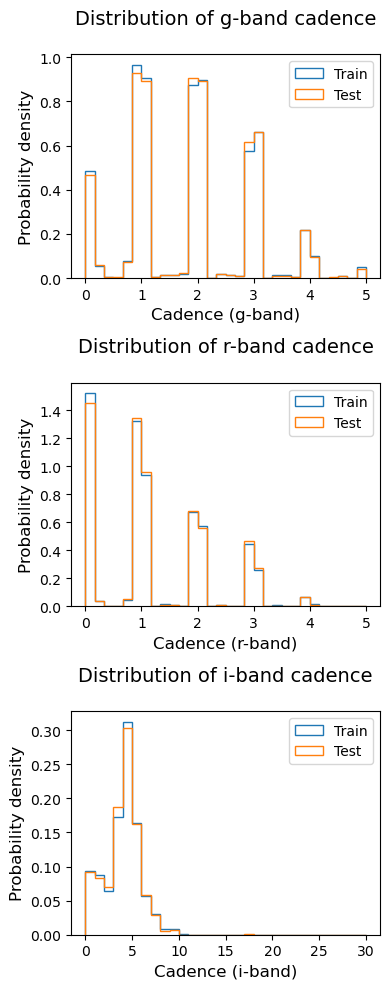

In [37]:
filter_dist = get_filter_distribution(dataset = train_stats, stat_name = 'cadence_median')
filter_dist_test = get_filter_distribution(dataset = test_stats, stat_name = 'cadence_median')
cut = [5, 5, 30]

fig, axes = plt.subplots(3, 1, figsize=(4, 10))
plt.title('Distribution of cadence_median')

for idx, (filter_name, counts) in enumerate(filter_dist.items()):
            
    axes[idx].hist(np.array(counts), histtype = 'step', bins=30, density = True, label = 'Train', range = (0, cut[idx]))
    axes[idx].hist(np.array(filter_dist_test[filter_name]), histtype = 'step', bins=30, density = True, label = 'Test', range = (0, cut[idx]))

    axes[idx].set_xlabel(f'Cadence ({filter_name}-band)', fontsize=12)
    axes[idx].set_ylabel('Probability density', fontsize=12)
    axes[idx].set_title(f'Distribution of {filter_name}-band cadence\n', 
                       fontsize=14)
    axes[idx].legend()
    
plt.tight_layout()
plt.savefig('images/Distribution of median cadence per filter.png')
plt.show()